# 7. Benchmarking computacional

**Qué se mide.** Tiempo de pared, memoria pico (proceso Python + hijos, que incluye la JVM de
Spark) y filas por segundo, por separado para lectura, preprocesamiento, entrenamiento y
predicción.

**Carga de trabajo comparable.** Para el punto de cruce y el escalamiento se fija la carga:
codificación por frecuencia ($d$ = 24), la mejor arquitectura de cada entorno y un número **fijo**
de épocas/iteraciones (el de la mejor configuración encontrada), sin parada temprana. Así el
tiempo depende del volumen y de los núcleos, no de cuándo se detuvo cada corrida.

**Experimentos.**
1. Desglose por etapa de las corridas de los capítulos 4 y 5.
2. Punto de cruce: volumen creciente, ambos entornos, todos los núcleos.
3. Escalamiento fuerte: tamaño fijo con 1, 2, 4 y 8 núcleos → $S(p) = T_1/T_p$, $E(p) = S(p)/p$ y
   ajuste de Amdahl $S(p) = 1/(s + (1-s)/p)$.
4. Escalamiento débil: tamaño proporcional a los núcleos ($E_w(p) = T_1/T_p$; ideal = 1).
5. Evidencia de la Spark UI y costo estimado en la nube.

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else str(Path.cwd() / "src"))
import numpy as np, pandas as pd, polars as pl, psutil
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score
from ctr.nbutils import setup, savefig, show, run_key, done_keys, SERIES, FRAMEWORK_COLOR, MUTED
from ctr import data, spark_ctr as S
from ctr.features import CTRFeaturizer
from ctr.models_sk import parse_hidden
from ctr.bench import measure, append_jsonl, read_jsonl, fit_amdahl, amdahl, hardware_info

cfg, RES, FIG = setup()
B = cfg["bench"]
BENCH = RES / "bench.jsonl"
HW = hardware_info(); print(HW)
CORES = [p for p in B["cores"] if p <= psutil.cpu_count()]
sk_best = json.loads((RES / "mlp_best_params.json").read_text())
sp_best = json.loads((RES / "spark_mlp_best_params.json").read_text())["freq"]
sk_trials = pd.read_csv(RES / "optuna_trials.csv").sort_values("value")
SK_EPOCHS = int(sk_trials.iloc[0].get("user_attrs_best_epoch", 10) or 10)
print("scikit-learn:", sk_best, "| épocas fijas:", SK_EPOCHS)
print("Spark:", sp_best)
va_pl, te_pl = data.eval_sets(cfg)
yte = te_pl["click"].to_numpy()
N_TRAIN = data.split_sizes(cfg)["train"]

Perfil: colab  |  resultados en: /content/deep-learning-01-ctr-mlp/results
{'sistema': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'procesador': 'x86_64', 'nucleos_fisicos': 4, 'nucleos_logicos': 8, 'ram_gb': 51.0, 'python': '3.13.18'}
scikit-learn: {'hidden_layer_sizes': '100', 'alpha': 0.04667993294288689, 'learning_rate_init': 0.00014659067019501246, 'batch_size': 2048, 'val_log_loss': 0.3860083222389221, 'busqueda_s': 2026.7151061429997} | épocas fijas: 13
Spark: {'hidden': [50], 'stepSize': 0.01, 'maxIter': 100, 'solver': 'l-bfgs'}


## 7.1 Desglose por etapa (corridas de los capítulos 4 y 5)

In [2]:
runs = pd.concat([read_jsonl(RES / "runs_sklearn.jsonl"), read_jsonl(RES / "runs_spark.jsonl")], ignore_index=True)
if "omitida" in runs:
    runs = runs[runs["omitida"].isna()]
st = (runs.groupby(["framework", "model", "encoding", "n"])
          [["lectura_s", "prep_s", "train_s", "predict_s", "prep_peak_mb", "train_peak_mb", "train_rows_per_s", "predict_rows_per_s"]]
          .median().reset_index())
st.to_csv(RES / "bench_etapas.csv", index=False)
show(st, 60, "{:.2f}")

,framework,model,encoding,n,lectura_s,prep_s,train_s,predict_s,prep_peak_mb,train_peak_mb,train_rows_per_s,predict_rows_per_s
0,sklearn,hgb,freq,100000,2.13,0.36,38.07,9.67,8308.08,4473.45,2626.80,436143.94
1,sklearn,hgb,freq,1000000,0.09,1.89,52.70,31.14,5275.12,4607.80,18976.95,135476.92
2,sklearn,hgb,freq,10000000,20.51,18.83,215.39,33.26,10545.80,8611.04,46427.43,126829.85
3,sklearn,hgb,target,100000,2.13,0.55,40.93,4.57,8308.08,4410.58,2443.29,923257.63
4,sklearn,hgb,target,1000000,0.09,5.29,48.07,6.72,4873.28,4610.97,20804.02,627996.14
5,sklearn,hgb,target,10000000,20.51,54.12,165.20,35.01,13218.13,8621.36,60533.54,120511.11
6,sklearn,mlp,freq,100000,2.13,0.36,14.14,0.67,8308.08,4591.04,7072.75,6290731.03
7,sklearn,mlp,freq,1000000,0.09,1.89,52.39,0.65,5275.12,4700.04,19088.72,6475636.36
8,sklearn,mlp,freq,10000000,20.51,18.83,183.96,0.69,10545.80,6457.49,54358.57,6153430.40
9,sklearn,mlp,hash,100000,2.13,0.32,35.78,2.99,8308.08,5134.72,2794.68,1410379.51


## 7.2 Funciones de carga fija

In [3]:
def sk_job(n, cores, rec):
    """Lectura + preprocesamiento + entrenamiento (épocas fijas) + predicción en scikit-learn."""
    need_gb = (n or N_TRAIN) * 24 * 4 * 3 / 2**30
    if need_gb > 0.7 * psutil.virtual_memory().available / 2**30:
        raise MemoryError(f"se estiman {need_gb:.1f} GB; supera el 70 % de la RAM disponible")
    feat = CTRFeaturizer(cfg.high_card, cfg.low_card, cfg["rare_min_count"])
    if n is None:   # entrenamiento completo: conteo en streaming y codificación por días
        lf = data.scan(cfg.path("parquet_dir")).filter(pl.col("day").is_in(cfg["split"]["train_days"]))
        with measure(rec, "lectura"):
            pass
        with measure(rec, "prep"):
            feat.fit_lazy(lf); codes, y = feat.encode_lazy(lf)
            X = feat.transform_codes(codes, "freq", y=y, fit=True); del codes
    else:
        with measure(rec, "lectura", n):
            tr = data.read_sample(cfg, "train", n)
        with measure(rec, "prep", n):
            y = tr["click"].to_numpy(); feat.fit(tr)
            X = feat.transform_codes(feat.encode(tr), "freq", y=y, fit=True); del tr
    Xte = feat.transform_codes(feat.encode(te_pl), "freq")
    with threadpool_limits(limits=cores):
        clf = MLPClassifier(hidden_layer_sizes=parse_hidden(sk_best["hidden_layer_sizes"]), alpha=sk_best["alpha"],
                            learning_rate_init=sk_best["learning_rate_init"], batch_size=int(sk_best["batch_size"]),
                            random_state=cfg["seed_base"])
        with measure(rec, "train", X.shape[0]):
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConvergenceWarning)
                for _ in range(SK_EPOCHS):
                    clf.partial_fit(X, y, classes=np.array([0, 1]))
        with measure(rec, "predict", Xte.shape[0]):
            p = clf.predict_proba(Xte)[:, 1]
    rec["n"] = X.shape[0]; rec["roc_auc"] = roc_auc_score(yte, p)


def sp_job(n, cores, rec, spark):
    """Lo mismo en Spark con local[cores]."""
    teS = spark.read.parquet(str(data.sample_path(cfg, "test", cfg["test_max_rows"])))
    with measure(rec, "lectura"):
        trS = S.read_train(spark, cfg, n, data.sample_path).cache(); rec["n"] = trS.count()
    with measure(rec, "prep", rec["n"]):
        feat = S.SparkFeaturizer(cfg.high_card, cfg.low_card, cfg["rare_min_count"]).fit(trS)
        trP, _, teP, d = S.prepare(feat, trS, teS, teS, "freq")
        trP = trP.cache(); trP.count(); teP = teP.cache(); teP.count()
    trS.unpersist()
    with measure(rec, "train", rec["n"]):
        model = S.make_model("mlp", d, sp_best, cfg["seed_base"]).fit(trP)
    with measure(rec, "predict", len(yte)):
        pr = S.predict_proba(model, teP)
    rec["roc_auc"] = roc_auc_score(yte, pr["p"]); trP.unpersist(); teP.unpersist()


def run_bench(exp, fw, n, cores, rep, spark=None):
    key = run_key(exp=exp, fw=fw, n=n if n is not None else "all", cores=cores, rep=rep)
    if key in done_b:
        return
    rec = {"key": key, "exp": exp, "framework": fw, "cores": cores, "rep": rep, "n_pedido": n}
    try:
        sk_job(n, cores, rec) if fw == "sklearn" else sp_job(n, cores, rec, spark)
        rec["total_s"] = sum(rec.get(f"{s}_s", 0) for s in ["lectura", "prep", "train", "predict"])
        rec["peak_mb"] = max(rec.get(f"{s}_peak_mb", 0) for s in ["lectura", "prep", "train", "predict"])
    except MemoryError as e:
        rec["fallo"] = f"memoria: {e}"
    except Exception as e:  # p. ej., OutOfMemoryError de la JVM
        rec["fallo"] = f"{type(e).__name__}: {str(e)[:200]}"
    append_jsonl(BENCH, rec)
    print(key, {k: round(v, 2) for k, v in rec.items() if k.endswith("_s") or k == "roc_auc"}, rec.get("fallo", ""))

done_b = done_keys(BENCH)

## 7.3 Punto de cruce (todos los núcleos)

cores=8|exp=cruce|fw=sklearn|n=100000|rep=0 {'lectura_s': 0.07, 'lectura_rows_per_s': 1536912.38, 'prep_s': 0.31, 'prep_rows_per_s': 318803.54, 'train_s': 5.66, 'train_rows_per_s': 17657.06, 'predict_s': 0.81, 'predict_rows_per_s': 5207735.58, 'roc_auc': 0.64, 'total_s': 6.85} 


cores=8|exp=cruce|fw=sklearn|n=300000|rep=0 {'lectura_s': 0.07, 'lectura_rows_per_s': 4226844.72, 'prep_s': 0.7, 'prep_rows_per_s': 427826.77, 'train_s': 14.19, 'train_rows_per_s': 21148.57, 'predict_s': 1.02, 'predict_rows_per_s': 4131302.91, 'roc_auc': 0.67, 'total_s': 15.98} 


cores=8|exp=cruce|fw=sklearn|n=1000000|rep=0 {'lectura_s': 0.23, 'lectura_rows_per_s': 4422586.2, 'prep_s': 1.9, 'prep_rows_per_s': 527235.0, 'train_s': 25.27, 'train_rows_per_s': 39570.68, 'predict_s': 0.66, 'predict_rows_per_s': 6427695.59, 'roc_auc': 0.69, 'total_s': 28.05} 


cores=8|exp=cruce|fw=sklearn|n=3000000|rep=0 {'lectura_s': 9.09, 'lectura_rows_per_s': 329905.51, 'prep_s': 4.97, 'prep_rows_per_s': 603686.7, 'train_s': 87.5, 'train_rows_per_s': 34285.15, 'predict_s': 0.79, 'predict_rows_per_s': 5336285.98, 'roc_auc': 0.68, 'total_s': 102.36} 


cores=8|exp=cruce|fw=sklearn|n=10000000|rep=0 {'lectura_s': 0.56, 'lectura_rows_per_s': 17897689.69, 'prep_s': 16.14, 'prep_rows_per_s': 619620.95, 'train_s': 253.37, 'train_rows_per_s': 39468.62, 'predict_s': 0.64, 'predict_rows_per_s': 6541377.98, 'roc_auc': 0.67, 'total_s': 270.71} 


cores=8|exp=cruce|fw=sklearn|n=100000|rep=1 {'lectura_s': 0.03, 'lectura_rows_per_s': 3976249.07, 'prep_s': 0.22, 'prep_rows_per_s': 452274.27, 'train_s': 2.11, 'train_rows_per_s': 47324.31, 'predict_s': 0.63, 'predict_rows_per_s': 6738507.12, 'roc_auc': 0.64, 'total_s': 2.99} 


... (12 outputs left out)

cores=8|exp=cruce|fw=spark|n=3000000|rep=1 {'lectura_s': 5.58, 'prep_s': 51.5, 'prep_rows_per_s': 58255.9, 'train_s': 97.49, 'train_rows_per_s': 30771.84, 'predict_s': 13.11, 'predict_rows_per_s': 321889.51, 'roc_auc': 0.66, 'total_s': 167.68} 


cores=8|exp=cruce|fw=spark|n=10000000|rep=1 {'lectura_s': 17.52, 'prep_s': 80.59, 'prep_rows_per_s': 124079.34, 'train_s': 278.27, 'train_rows_per_s': 35935.95, 'predict_s': 13.41, 'predict_rows_per_s': 314594.96, 'roc_auc': 0.65, 'total_s': 389.8} 


,framework,n,lectura_s,prep_s,train_s,predict_s,total_s,peak_mb,roc_auc
0,sklearn,100000,0.045,0.267,3.888,0.718,4.919,4608.746,0.641
1,sklearn,300000,0.051,0.642,11.130,0.837,12.661,4673.852,0.669
2,sklearn,1000000,0.149,1.808,25.234,0.652,27.843,4712.906,0.686
3,sklearn,3000000,4.633,4.866,82.106,0.743,92.348,5906.594,0.678
4,sklearn,10000000,0.560,15.877,260.739,0.657,277.833,10653.549,0.666
5,spark,100000,2.185,33.024,15.313,14.024,64.547,23073.490,0.683
6,spark,300000,1.530,31.430,25.964,13.164,72.088,24998.727,0.683
7,spark,1000000,2.230,36.397,38.990,13.705,91.322,24985.158,0.650
8,spark,3000000,5.561,52.732,96.736,13.166,168.195,25169.102,0.662
9,spark,10000000,18.052,92.621,279.069,13.329,403.071,28873.904,0.651


Punto de cruce estimado (filas): {'train_s': 'no se observa en el rango medido', 'total_s': 'no se observa en el rango medido'}


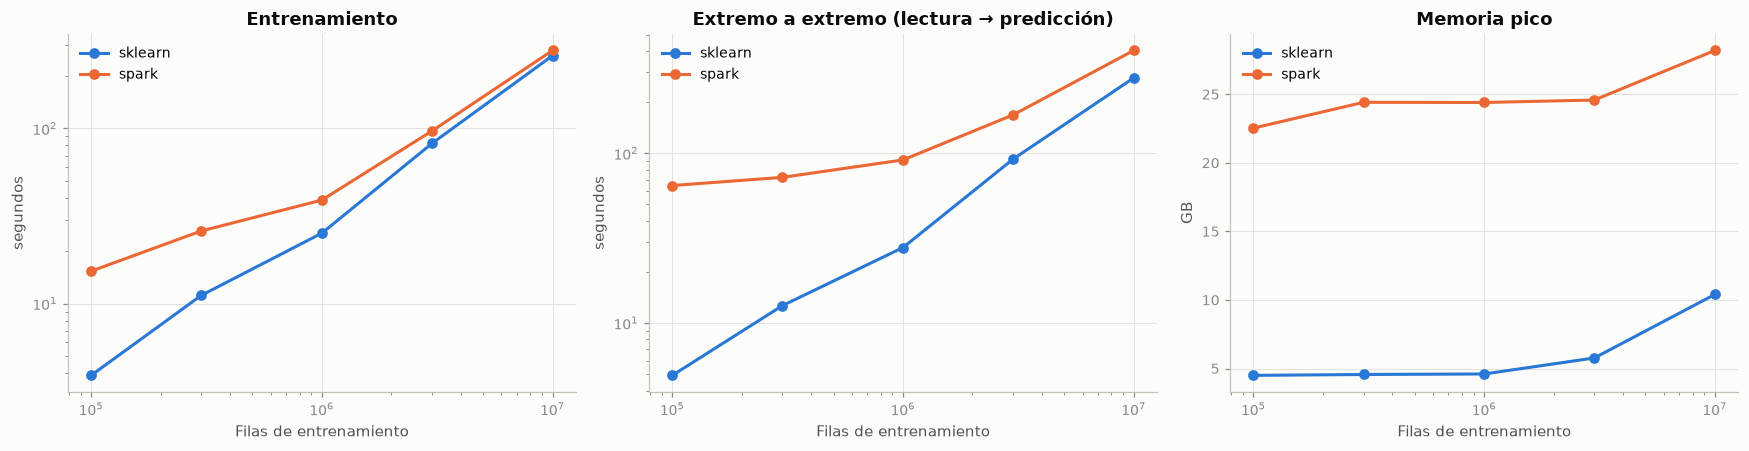

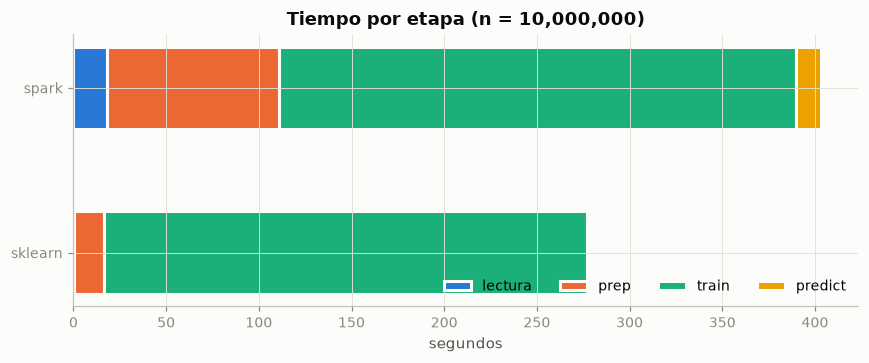

In [4]:
allc = max(CORES)
for rep in range(B["reps"]):
    for n in B["crossover_sizes"]:
        run_bench("cruce", "sklearn", n, allc, rep)
spark = S.get_spark(cfg, allc)
for rep in range(B["reps"]):
    for n in B["crossover_sizes"]:
        run_bench("cruce", "spark", n, allc, rep, spark)
ui = S.ui_stage_metrics(spark); ui.to_csv(RES / "spark_ui_cruce.csv", index=False)
spark.stop()

bench = read_jsonl(BENCH)
ok = bench[bench["fallo"].isna()] if "fallo" in bench else bench
cr = (ok[ok.exp == "cruce"].groupby(["framework", "n"])
        [["lectura_s", "prep_s", "train_s", "predict_s", "total_s", "peak_mb", "roc_auc"]].median().reset_index())
show(cr, 40, "{:.3f}")
if "fallo" in bench:
    show(bench[bench["fallo"].notna()][["exp", "framework", "n_pedido", "cores", "fallo"]])

def crossover(cr, col):
    a = cr[cr.framework == "sklearn"].set_index("n")[col]; b = cr[cr.framework == "spark"].set_index("n")[col]
    ns = sorted(set(a.index) & set(b.index))
    diff = [(n, np.log(b[n]) - np.log(a[n])) for n in ns]
    for (n0, d0), (n1, d1) in zip(diff, diff[1:]):
        if d0 > 0 >= d1:   # Spark pasa de más lento a más rápido: interpolación log-log
            return float(np.exp(np.log(n0) + (np.log(n1) - np.log(n0)) * d0 / (d0 - d1)))
    return None

cruce = {c: crossover(cr, c) for c in ["train_s", "total_s"]}
print("Punto de cruce estimado (filas):", {k: (f"{v:,.0f}" if v else "no se observa en el rango medido") for k, v in cruce.items()})
(RES / "punto_cruce.json").write_text(json.dumps(cruce))

fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
for fw, g in cr.groupby("framework"):
    axs[0].plot(g["n"], g["train_s"], marker="o", color=FRAMEWORK_COLOR[fw], label=fw)
    axs[1].plot(g["n"], g["total_s"], marker="o", color=FRAMEWORK_COLOR[fw], label=fw)
    axs[2].plot(g["n"], g["peak_mb"] / 1024, marker="o", color=FRAMEWORK_COLOR[fw], label=fw)
for ax, t, yl, key in zip(axs, ["Entrenamiento", "Extremo a extremo (lectura → predicción)", "Memoria pico"],
                          ["segundos", "segundos", "GB"], ["train_s", "total_s", None]):
    ax.set_xscale("log"); ax.set_xlabel("Filas de entrenamiento"); ax.set_title(t); ax.set_ylabel(yl); ax.legend()
    if key:
        ax.set_yscale("log")
        if cruce.get(key):
            ax.axvline(cruce[key], color=MUTED, linestyle="--", linewidth=1)
            ax.text(cruce[key], ax.get_ylim()[1], " cruce", color=MUTED, va="top", fontsize=8)
savefig(fig, FIG, "07_punto_cruce")

# barras comparativas por etapa en el mayor tamaño común
nmax = cr.groupby("n")["framework"].nunique().loc[lambda s: s == 2].index.max()
g = cr[cr.n == nmax].set_index("framework")[["lectura_s", "prep_s", "train_s", "predict_s"]]
fig, ax = plt.subplots(figsize=(8, 3.4))
left = np.zeros(len(g))
for i, c in enumerate(g.columns):
    ax.barh(g.index, g[c], left=left, color=SERIES[i], label=c.replace("_s", ""), height=0.5, edgecolor="#fcfcfb", linewidth=2)
    left += g[c].values
ax.set_xlabel("segundos"); ax.set_title(f"Tiempo por etapa (n = {int(nmax):,})"); ax.legend(ncols=4, loc="lower right")
savefig(fig, FIG, "07_etapas")

## 7.4 Escalamiento fuerte (tamaño fijo) y ley de Amdahl

cores=1|exp=fuerte|fw=sklearn|n=1000000|rep=0 {'lectura_s': 0.12, 'lectura_rows_per_s': 8456935.03, 'prep_s': 1.81, 'prep_rows_per_s': 551955.75, 'train_s': 16.49, 'train_rows_per_s': 60640.46, 'predict_s': 1.18, 'predict_rows_per_s': 3584796.87, 'roc_auc': 0.69, 'total_s': 19.6} 


cores=2|exp=fuerte|fw=sklearn|n=1000000|rep=0 {'lectura_s': 0.07, 'lectura_rows_per_s': 14797051.78, 'prep_s': 2.16, 'prep_rows_per_s': 463391.74, 'train_s': 17.16, 'train_rows_per_s': 58277.18, 'predict_s': 0.96, 'predict_rows_per_s': 4372976.5, 'roc_auc': 0.69, 'total_s': 20.35} 


cores=4|exp=fuerte|fw=sklearn|n=1000000|rep=0 {'lectura_s': 0.2, 'lectura_rows_per_s': 5109209.38, 'prep_s': 1.93, 'prep_rows_per_s': 518035.82, 'train_s': 15.91, 'train_rows_per_s': 62853.0, 'predict_s': 0.68, 'predict_rows_per_s': 6212618.92, 'roc_auc': 0.69, 'total_s': 18.72} 


cores=8|exp=fuerte|fw=sklearn|n=1000000|rep=0 {'lectura_s': 0.07, 'lectura_rows_per_s': 13847469.57, 'prep_s': 1.77, 'prep_rows_per_s': 565073.72, 'train_s': 29.12, 'train_rows_per_s': 34340.0, 'predict_s': 0.82, 'predict_rows_per_s': 5130767.67, 'roc_auc': 0.69, 'total_s': 31.78} 


cores=1|exp=fuerte|fw=sklearn|n=1000000|rep=1 {'lectura_s': 0.26, 'lectura_rows_per_s': 3875338.14, 'prep_s': 1.85, 'prep_rows_per_s': 539167.8, 'train_s': 15.58, 'train_rows_per_s': 64171.91, 'predict_s': 1.41, 'predict_rows_per_s': 2982484.05, 'roc_auc': 0.69, 'total_s': 19.11} 


cores=2|exp=fuerte|fw=sklearn|n=1000000|rep=1 {'lectura_s': 0.06, 'lectura_rows_per_s': 15395932.58, 'prep_s': 1.71, 'prep_rows_per_s': 585762.16, 'train_s': 16.27, 'train_rows_per_s': 61468.3, 'predict_s': 0.94, 'predict_rows_per_s': 4490988.24, 'roc_auc': 0.69, 'total_s': 18.98} 


... (7 outputs left out)

cores=4|exp=fuerte|fw=spark|n=1000000|rep=1 {'lectura_s': 2.36, 'prep_s': 25.97, 'prep_rows_per_s': 38504.48, 'train_s': 43.47, 'train_rows_per_s': 23005.49, 'predict_s': 12.57, 'predict_rows_per_s': 335600.56, 'roc_auc': 0.65, 'total_s': 84.37} 


cores=8|exp=fuerte|fw=spark|n=1000000|rep=0 {'lectura_s': 3.05, 'prep_s': 42.18, 'prep_rows_per_s': 23709.75, 'train_s': 40.66, 'train_rows_per_s': 24596.8, 'predict_s': 13.31, 'predict_rows_per_s': 316876.45, 'roc_auc': 0.65, 'total_s': 99.2} 


cores=8|exp=fuerte|fw=spark|n=1000000|rep=1 {'lectura_s': 2.76, 'prep_s': 31.87, 'prep_rows_per_s': 31381.2, 'train_s': 39.41, 'train_rows_per_s': 25375.17, 'predict_s': 13.69, 'predict_rows_per_s': 308260.23, 'roc_auc': 0.65, 'total_s': 87.72} 


,framework,fraccion_secuencial,se,aceleracion_max_teorica
0,sklearn,1.0000,0.1907,1.0000
1,spark,0.2055,0.0219,4.8659


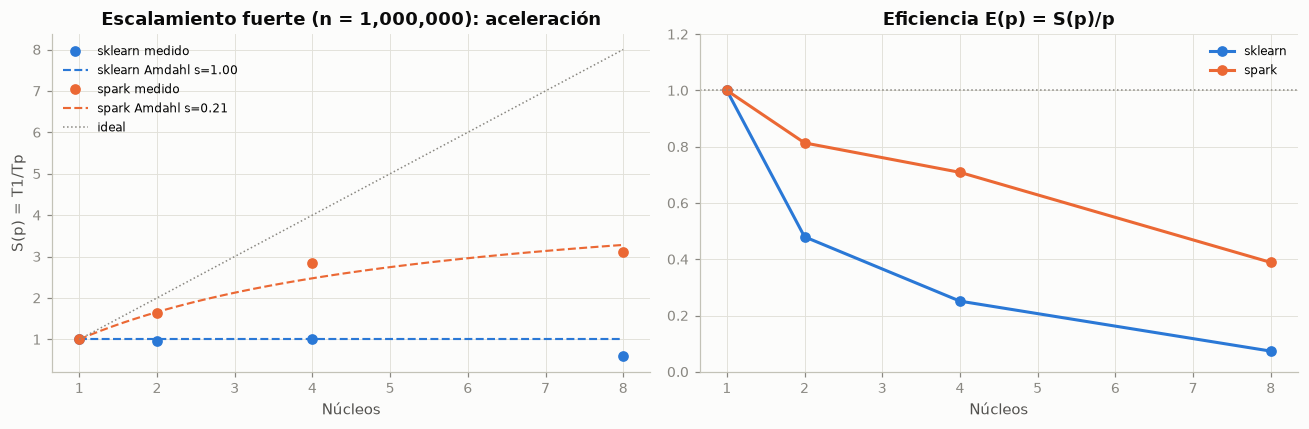

In [5]:
NS = B["strong_size"]
for rep in range(B["reps"]):
    for p in CORES:
        run_bench("fuerte", "sklearn", NS, p, rep)
for p in CORES:
    spark = S.get_spark(cfg, p)
    for rep in range(B["reps"]):
        run_bench("fuerte", "spark", NS, p, rep, spark)
    spark.stop()

bench = read_jsonl(BENCH); ok = bench[bench["fallo"].isna()] if "fallo" in bench else bench
fu = ok[ok.exp == "fuerte"].groupby(["framework", "cores"])[["train_s", "total_s"]].median().reset_index()
am_rows = []
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
pp = np.linspace(1, max(CORES), 50)
for fw, g in fu.groupby("framework"):
    g = g.sort_values("cores")
    if len(g) < 2:
        continue
    fa = fit_amdahl(g["cores"], g["train_s"])
    am_rows.append({"framework": fw, **{k: v for k, v in fa.items() if not isinstance(v, list)}})
    axs[0].plot(g["cores"], fa["speedup"], "o", color=FRAMEWORK_COLOR[fw], label=f"{fw} medido")
    axs[0].plot(pp, amdahl(pp, fa["fraccion_secuencial"]), color=FRAMEWORK_COLOR[fw], linewidth=1.4, linestyle="--",
                label=f"{fw} Amdahl s={fa['fraccion_secuencial']:.2f}")
    axs[1].plot(g["cores"], fa["eficiencia"], marker="o", color=FRAMEWORK_COLOR[fw], label=fw)
axs[0].plot(pp, pp, color=MUTED, linewidth=1, linestyle=":", label="ideal")
axs[0].set(title=f"Escalamiento fuerte (n = {NS:,}): aceleración", xlabel="Núcleos", ylabel="S(p) = T1/Tp")
axs[1].axhline(1, color=MUTED, linewidth=1, linestyle=":"); axs[1].set(title="Eficiencia E(p) = S(p)/p", xlabel="Núcleos", ylim=(0, 1.2))
axs[0].legend(fontsize=8); axs[1].legend(fontsize=8)
savefig(fig, FIG, "07_escalamiento_fuerte")
amd = pd.DataFrame(am_rows); amd.to_csv(RES / "amdahl.csv", index=False); show(amd)

## 7.5 Escalamiento débil (tamaño ∝ núcleos)

cores=1|exp=debil|fw=sklearn|n=500000|rep=0 {'lectura_s': 3.8, 'lectura_rows_per_s': 131413.35, 'prep_s': 0.98, 'prep_rows_per_s': 509622.4, 'train_s': 7.69, 'train_rows_per_s': 64988.27, 'predict_s': 1.34, 'predict_rows_per_s': 3142597.95, 'roc_auc': 0.68, 'total_s': 13.82} 


cores=2|exp=debil|fw=sklearn|n=1000000|rep=0 {'lectura_s': 0.06, 'lectura_rows_per_s': 15479972.49, 'prep_s': 1.69, 'prep_rows_per_s': 592333.89, 'train_s': 16.1, 'train_rows_per_s': 62095.63, 'predict_s': 0.8, 'predict_rows_per_s': 5242595.79, 'roc_auc': 0.69, 'total_s': 18.66} 


cores=4|exp=debil|fw=sklearn|n=2000000|rep=0 {'lectura_s': 6.43, 'lectura_rows_per_s': 310864.22, 'prep_s': 5.31, 'prep_rows_per_s': 376934.64, 'train_s': 32.59, 'train_rows_per_s': 61370.86, 'predict_s': 0.8, 'predict_rows_per_s': 5250486.5, 'roc_auc': 0.69, 'total_s': 45.13} 


cores=8|exp=debil|fw=sklearn|n=4000000|rep=0 {'lectura_s': 9.24, 'lectura_rows_per_s': 433035.88, 'prep_s': 6.68, 'prep_rows_per_s': 598381.82, 'train_s': 100.86, 'train_rows_per_s': 39657.44, 'predict_s': 0.69, 'predict_rows_per_s': 6081410.62, 'roc_auc': 0.68, 'total_s': 117.48} 


cores=1|exp=debil|fw=sklearn|n=500000|rep=1 {'lectura_s': 0.05, 'lectura_rows_per_s': 11077583.45, 'prep_s': 0.91, 'prep_rows_per_s': 546926.32, 'train_s': 7.74, 'train_rows_per_s': 64618.42, 'predict_s': 1.43, 'predict_rows_per_s': 2946775.71, 'roc_auc': 0.68, 'total_s': 10.13} 


cores=2|exp=debil|fw=sklearn|n=1000000|rep=1 {'lectura_s': 0.08, 'lectura_rows_per_s': 12913351.87, 'prep_s': 1.72, 'prep_rows_per_s': 582636.66, 'train_s': 16.2, 'train_rows_per_s': 61725.76, 'predict_s': 0.97, 'predict_rows_per_s': 4361629.26, 'roc_auc': 0.69, 'total_s': 18.96} 


... (7 outputs left out)

cores=4|exp=debil|fw=spark|n=2000000|rep=1 {'lectura_s': 5.68, 'prep_s': 42.88, 'prep_rows_per_s': 46640.21, 'train_s': 83.5, 'train_rows_per_s': 23950.89, 'predict_s': 13.1, 'predict_rows_per_s': 322033.17, 'roc_auc': 0.67, 'total_s': 145.17} 


cores=8|exp=debil|fw=spark|n=4000000|rep=0 {'lectura_s': 8.56, 'prep_s': 64.2, 'prep_rows_per_s': 62306.01, 'train_s': 119.5, 'train_rows_per_s': 33472.41, 'predict_s': 14.18, 'predict_rows_per_s': 297433.03, 'roc_auc': 0.66, 'total_s': 206.45} 


cores=8|exp=debil|fw=spark|n=4000000|rep=1 {'lectura_s': 8.47, 'prep_s': 40.31, 'prep_rows_per_s': 99233.19, 'train_s': 118.89, 'train_rows_per_s': 33644.47, 'predict_s': 13.86, 'predict_rows_per_s': 304501.33, 'roc_auc': 0.66, 'total_s': 181.52} 


,framework,cores,train_s,n
0,sklearn,1,7.7157,500000.0000
1,sklearn,2,16.1524,1000000.0000
2,sklearn,4,32.3467,2000000.0000
3,sklearn,8,100.3723,4000000.0000
4,spark,1,62.0006,500000.0000
5,spark,2,76.9258,1000000.0000
6,spark,4,86.3329,2000000.0000
7,spark,8,119.1958,4000000.0000


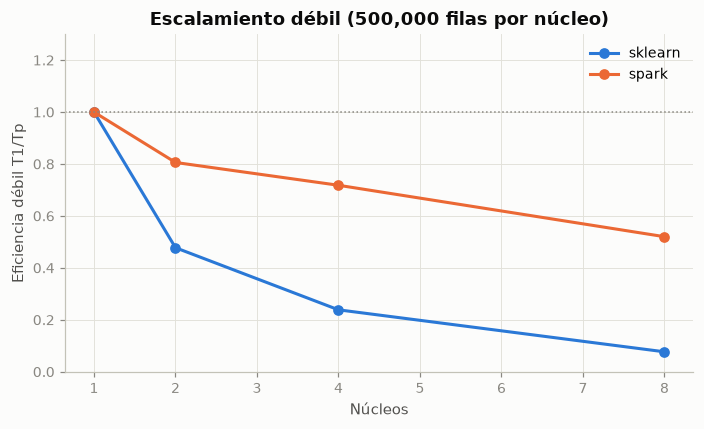

In [6]:
for rep in range(B["reps"]):
    for p in CORES:
        run_bench("debil", "sklearn", B["weak_base"] * p, p, rep)
for p in CORES:
    spark = S.get_spark(cfg, p)
    for rep in range(B["reps"]):
        run_bench("debil", "spark", B["weak_base"] * p, p, rep, spark)
    spark.stop()
bench = read_jsonl(BENCH); ok = bench[bench["fallo"].isna()] if "fallo" in bench else bench
de = ok[ok.exp == "debil"].groupby(["framework", "cores"])[["train_s", "n"]].median().reset_index()
fig, ax = plt.subplots(figsize=(6.5, 4))
for fw, g in de.groupby("framework"):
    g = g.sort_values("cores")
    ax.plot(g["cores"], g["train_s"].iloc[0] / g["train_s"], marker="o", color=FRAMEWORK_COLOR[fw], label=fw)
ax.axhline(1, color=MUTED, linewidth=1, linestyle=":")
ax.set(title=f"Escalamiento débil ({B['weak_base']:,} filas por núcleo)", xlabel="Núcleos", ylabel="Eficiencia débil T1/Tp", ylim=(0, 1.3))
ax.legend()
savefig(fig, FIG, "07_escalamiento_debil")
show(de)

## 7.6 Spark UI y costo en la nube

El costo se calcula como (tiempo total en horas) × (precio por hora de la instancia), con el
precio que se defina en `config.yaml` (`cloud_price_usd_per_hour`). Verifique el precio vigente en
la página del proveedor el día de la entrega y regístrelo con fecha.

In [7]:
ui = pd.read_csv(RES / "spark_ui_cruce.csv")
if "shuffleWriteBytes" in ui:
    print({"etapas": len(ui), "shuffle_GB": (ui["shuffleReadBytes"].sum() + ui["shuffleWriteBytes"].sum()) / 2**30,
           "spill_disco_GB": ui["diskBytesSpilled"].sum() / 2**30,
           "sesgo_p95": float(ui["sesgo_max_sobre_mediana"].quantile(0.95))})
price = B["cloud_price_usd_per_hour"]
if price:
    cr["costo_usd"] = cr["total_s"] / 3600 * price
    show(cr[["framework", "n", "total_s", "costo_usd"]], 40, "{:.4f}")
else:
    print("Defina cloud_price_usd_per_hour en config.yaml para estimar el costo.")

{'etapas': 994, 'shuffle_GB': np.float64(0.04888416267931461), 'spill_disco_GB': np.float64(0.0), 'sesgo_p95': 1.171225497244189}
Defina cloud_price_usd_per_hour en config.yaml para estimar el costo.
